In [31]:
import numpy as np
import pandas as pd
from pathlib import Path

file_path = Path("MonthlyMeanTemp15points.txt")

In [32]:
# 1行目から観測所名を読み込む
with file_path.open(encoding="utf-8") as f:
    station_names = f.readline().split()[1:]

# 1〜3行目は地点情報なので飛ばす
data = pd.read_csv(
    file_path, sep=r"\s+", skiprows=3, header=None,
    names=["年月", *station_names]
)
data["年月"] = pd.to_datetime(data["年月"], format="%Y/%m")

In [33]:
# s252613なので、1月だけを取り出し、年 × 地点 の行列にする
january = data.loc[data["年月"].dt.month == 1]
X = january[station_names].to_numpy(dtype=float)

n, p = X.shape
assert p == 15

# 各地点の期間平均値を引く（Zの形状: n × p）
Z = X - X.mean(axis=0)

print(f"解析期間: {january['年月'].dt.year.iloc[0]}〜{january['年月'].dt.year.iloc[-1]}年")
print(f"n = {n}, p = {p}, Z.shape = {Z.shape}")

解析期間: 1898〜2023年
n = 126, p = 15, Z.shape = (126, 15)


In [34]:
# 共分散行列 C（p × p）
C = Z.T @ Z / (n - 1)

# 対称行列用の固有値・固有ベクトル計算
# eigvecs の各列が対応する固有ベクトル
eigvals, eigvecs = np.linalg.eigh(C)

# 固有値の大きい順に並べ替える
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

In [35]:
# 固有ベクトル：行が地点、列が主成分
vectors = pd.DataFrame(
    eigvecs,
    index=station_names,
    columns=[f"mode{i+1}" for i in range(p)]
)
print("固有ベクトル（各列が1つの固有ベクトル）:")
display(vectors.round(4))

固有ベクトル（各列が1つの固有ベクトル）:


,mode1,mode2,mode3,mode4,mode5,mode6,mode7,mode8,mode9,mode10,mode11,mode12,mode13,mode14,mode15
Abashiri,-0.2951,-0.4949,-0.3727,0.1932,0.0368,-0.1193,-0.0599,0.0315,-0.0388,-0.1605,-0.1627,-0.3350,-0.4728,0.2827,0.0465
Nemuro,-0.2567,-0.4747,-0.3180,0.1631,0.1010,-0.1576,-0.0761,-0.0683,0.0436,0.0087,0.2303,0.3805,0.4550,-0.3578,-0.0286
Suttsu,-0.2569,-0.3317,0.0953,-0.5791,0.2118,0.4923,0.2717,-0.0455,-0.0760,0.3132,0.0160,-0.0130,-0.0516,0.0064,-0.0970
Yamagata,-0.3074,-0.0721,0.3044,-0.1771,-0.5398,-0.2526,-0.1461,0.0498,-0.3326,0.0015,0.3330,0.3001,-0.1836,0.2116,-0.0846
Ishinomaki,-0.3074,-0.1301,0.2890,-0.1638,-0.3622,0.0948,-0.1479,0.0613,0.3281,-0.3428,-0.4281,-0.2124,0.3407,-0.1132,0.1731
Fushiki,-0.2910,0.1411,0.1883,-0.0081,0.1762,-0.2733,0.5624,0.1173,0.1201,-0.2651,0.2992,-0.1296,-0.2163,-0.3533,0.2476
Iida,-0.2614,0.1272,0.1312,0.4855,-0.0151,0.5677,0.0420,-0.4354,-0.2584,-0.2423,0.0934,0.0741,-0.0142,0.0195,0.0920
Choshi,-0.2791,0.0633,0.1208,0.4377,-0.1728,0.0621,0.1569,0.1953,0.4614,0.6003,-0.0837,0.1115,-0.0939,0.0844,-0.0822
Sakai,-0.2763,0.2140,-0.0088,-0.1653,0.4035,-0.1957,-0.0634,-0.2106,0.2377,-0.0741,-0.0392,0.3037,0.1464,0.5896,0.2760
Hamada,-0.2465,0.1993,0.0789,-0.1089,0.2406,-0.0262,-0.4733,-0.1955,0.2810,-0.0992,0.0499,-0.0096,-0.3222,-0.3041,-0.5225


In [36]:
#「固有値の和が Z の分散の和に等しいことを数値的に確かめよ。」

# Cの固有値の和
sum_eigvals = np.sum(eigvals)

# Zの各地点の分散の和
sum_var = np.sum(np.var(Z, axis=0, ddof=1))

print(f"Cの固有値の和 : {sum_eigvals:.10f}")
print(f"Zの分散の和   : {sum_var:.10f}")

Cの固有値の和 : 26.7690711111
Zの分散の和   : 26.7690711111


In [37]:
#「各モードの（有次元の）主成分時系列の分散が固有値と等しいことを数値的に確かめよ。」

# 各モードの主成分時系列（n × p）
PC = Z @ eigvecs

# 各モードの主成分時系列の分散
PC_var = np.var(PC, axis=0, ddof=1)

# 固有値との比較
for i in range(p):
    print(f"Mode {i+1:2d}: 分散 = {PC_var[i]:.6f}, "
          f"固有値 = {eigvals[i]:.6f}, ")

Mode  1: 分散 = 18.061094, 固有値 = 18.061094, 
Mode  2: 分散 = 6.069079, 固有値 = 6.069079, 
Mode  3: 分散 = 0.995153, 固有値 = 0.995153, 
Mode  4: 分散 = 0.413377, 固有値 = 0.413377, 
Mode  5: 分散 = 0.278649, 固有値 = 0.278649, 
Mode  6: 分散 = 0.233353, 固有値 = 0.233353, 
Mode  7: 分散 = 0.175326, 固有値 = 0.175326, 
Mode  8: 分散 = 0.136434, 固有値 = 0.136434, 
Mode  9: 分散 = 0.100974, 固有値 = 0.100974, 
Mode 10: 分散 = 0.078320, 固有値 = 0.078320, 
Mode 11: 分散 = 0.065496, 固有値 = 0.065496, 
Mode 12: 分散 = 0.055669, 固有値 = 0.055669, 
Mode 13: 分散 = 0.047156, 固有値 = 0.047156, 
Mode 14: 分散 = 0.037221, 固有値 = 0.037221, 
Mode 15: 分散 = 0.021771, 固有値 = 0.021771, 


In [ ]:
# 「第 3 モードまでの各モードについて、寄与率を数値で、
# 規格化された主成分時系列をグラフで示し、
# 有次元化した因子負荷量（経験直交関数パターン）を数値もしくは地図上に示せ。単位も適切に付記せよ」

# 寄与率
explained_ratio = eigvals / np.sum(eigvals)

for mode in range(3):
    print(f"mode{mode+1}: {explained_ratio[mode]*100:.2f} %")

mode1: 67.47 %
mode2: 22.67 %
mode3: 3.72 %


In [39]:
# 主成分時系列（有次元, 単位: ℃）
PC = Z @ eigvecs

# 規格化された主成分時系列（無次元）
# 各モードの分散が1になるように規格化
PC_norm = PC / np.sqrt(eigvals)

# 有次元化した因子負荷量（経験直交関数パターン）
# Z = PC_norm @ loadings.T と書けるような量
# 単位: ℃
loadings = eigvecs * np.sqrt(eigvals)

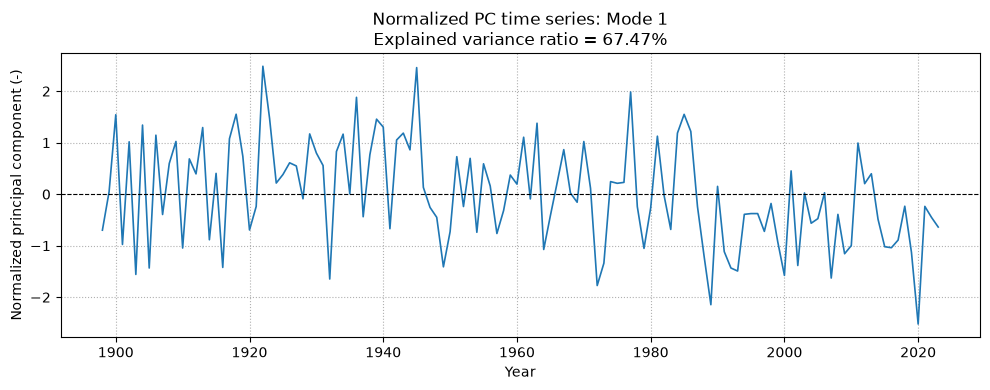

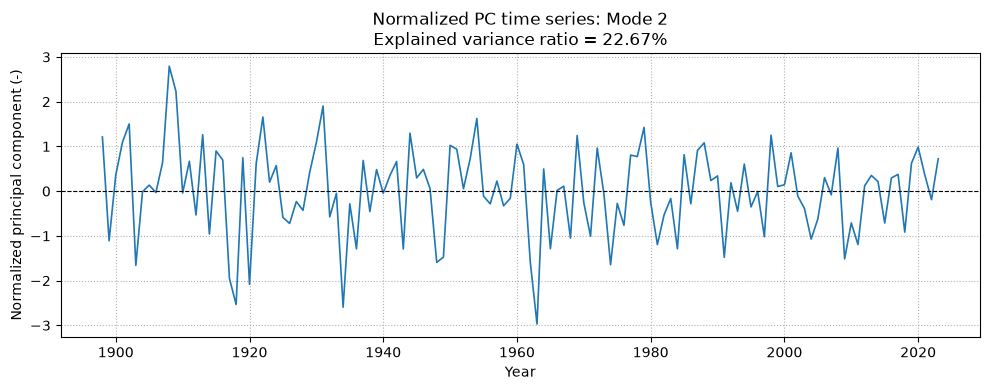

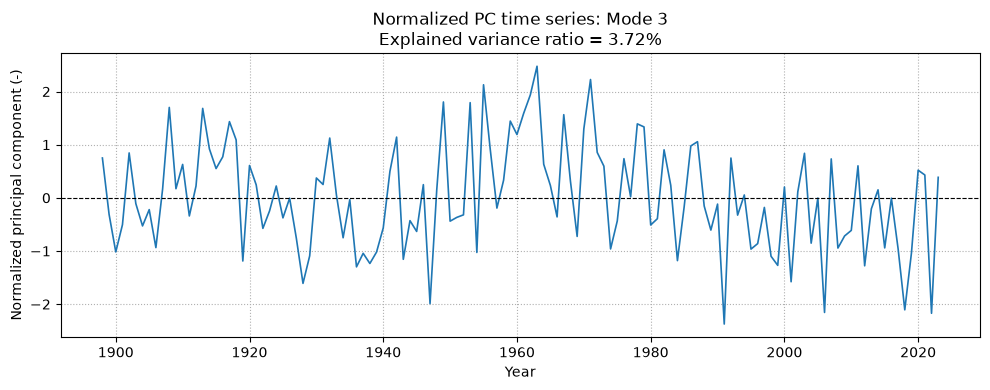

In [40]:
# 1月のデータに対応する年を取得
years = january["年月"].dt.year.to_numpy()

# 規格化された主成分時系列（無次元）を描画 (mode1,2,3)
import matplotlib.pyplot as plt

for mode in range(3):
    plt.figure(figsize=(10, 4))
    plt.plot(years, PC_norm[:, mode], linewidth=1.2)
    plt.axhline(0, color='k', linestyle='--', linewidth=0.8)
    plt.xlabel("Year")
    plt.ylabel("Normalized principal component (-)")
    plt.title(f"Normalized PC time series: Mode {mode+1}\n"
              f"Explained variance ratio = {explained_ratio[mode]*100:.2f}%")
    plt.grid(True, linestyle=':')
    plt.tight_layout()
    plt.show()

In [41]:
from pathlib import Path
import numpy as np

# 元データを読み込む
file_path = Path("MonthlyMeanTemp15points.txt")

with file_path.open(encoding="utf-8") as f:
    lines = f.readlines()

# 観測所名・緯度・経度を取得
station_names = lines[0].split()[1:]
latitudes = np.array(lines[1].split()[1:], dtype=float)
longitudes = np.array(lines[2].split()[1:], dtype=float)

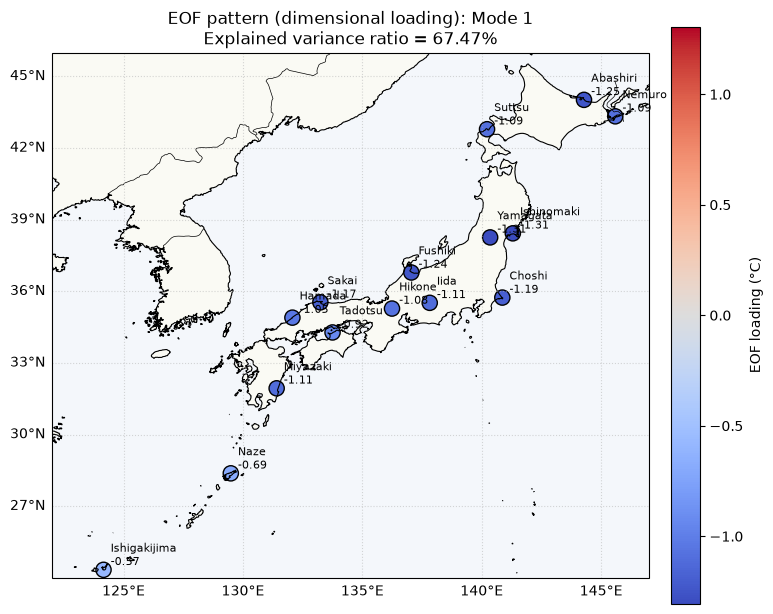

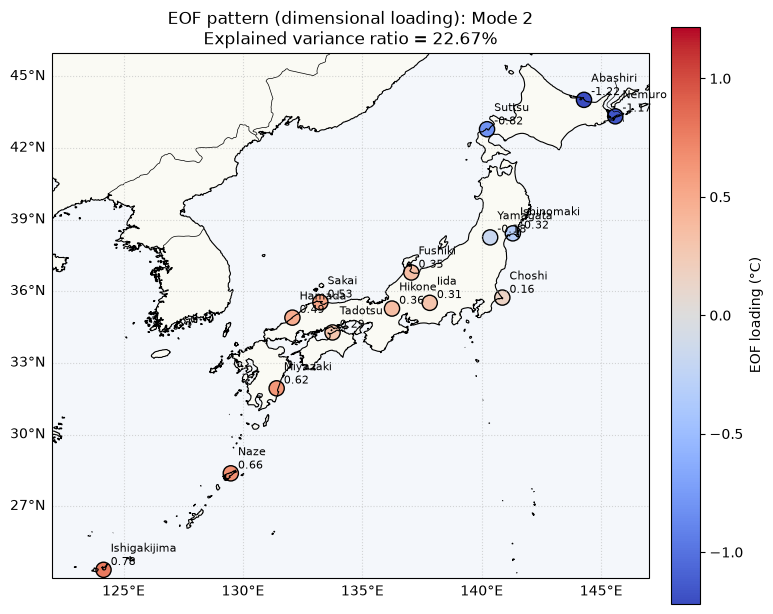

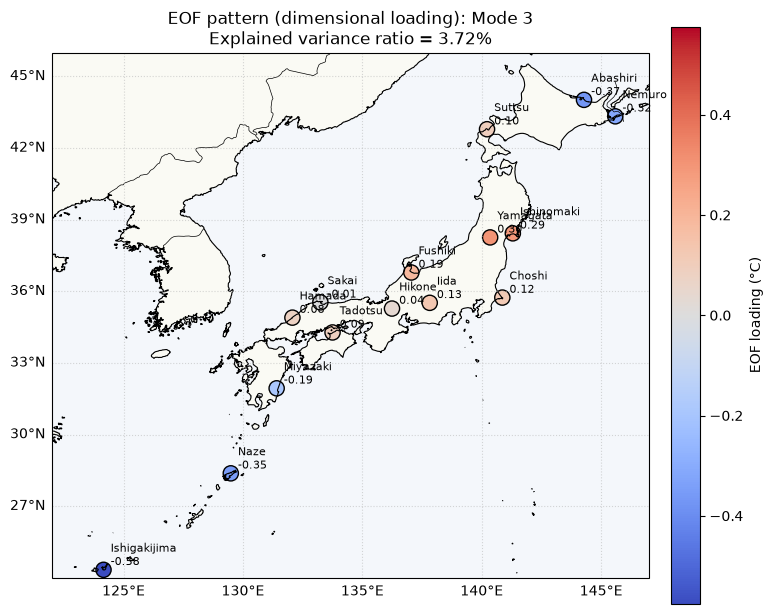

In [42]:
#有次元化した因子負荷量（経験直交関数パターン）を地図上に示す
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

for mode in range(3):
    fig = plt.figure(figsize=(8, 8))
    ax = plt.axes(projection=ccrs.PlateCarree())

    # 日本周辺
    ax.set_extent([122, 147, 24, 46], crs=ccrs.PlateCarree())

    ax.coastlines(resolution='10m', linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, alpha=0.3)
    ax.add_feature(cfeature.OCEAN, alpha=0.1)
    gl = ax.gridlines(draw_labels=True, linestyle=':', alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False

    # 各地点の因子負荷量（単位：℃）
    values = loadings[:, mode]

    # 0℃をカラーマップの中央に固定
    vmax = np.max(np.abs(values))
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

    sc = ax.scatter(
        longitudes, latitudes,
        c=values,
        s=120,
        cmap='coolwarm',
        norm=norm,
        edgecolor='k',
        transform=ccrs.PlateCarree()
    )

    # 観測所名を表示
    for lon, lat, name, val in zip(longitudes, latitudes, station_names, values):
        ax.text(lon + 0.3, lat + 0.2,
                f"{name}\n{val:.2f}",
                fontsize=8,
                transform=ccrs.PlateCarree())

    cbar = plt.colorbar(sc, ax=ax, shrink=0.75, pad=0.03)
    cbar.set_label("EOF loading (°C)")

    plt.title(f"EOF pattern (dimensional loading): Mode {mode+1}\n"
              f"Explained variance ratio = {explained_ratio[mode]*100:.2f}%")
    plt.tight_layout()
    plt.show()

In [ ]:
# 「CとGとでゼロでない固有値が一致することを確かめよ。」

# 行列 G の計算
n, p = Z.shape
G = Z @ Z.T / (n - 1)

# 固有値・固有ベクトルの計算
eigvals_G, eigvecs_G = np.linalg.eigh(G)

# 固有値の大きい順に並べ替え
idx = np.argsort(eigvals_G)[::-1]
eigvals_G = eigvals_G[idx]
eigvecs_G = eigvecs_G[:, idx]

# CとGの固有値を比較
for i in range(p):
    print(f"Mode {i+1:2d}: "
          f"C = {eigvals[i]:.6f}, "
          f"G = {eigvals_G[i]:.6f}, ")

Mode  1: C = 18.061094, G = 18.061094, 
Mode  2: C = 6.069079, G = 6.069079, 
Mode  3: C = 0.995153, G = 0.995153, 
Mode  4: C = 0.413377, G = 0.413377, 
Mode  5: C = 0.278649, G = 0.278649, 
Mode  6: C = 0.233353, G = 0.233353, 
Mode  7: C = 0.175326, G = 0.175326, 
Mode  8: C = 0.136434, G = 0.136434, 
Mode  9: C = 0.100974, G = 0.100974, 
Mode 10: C = 0.078320, G = 0.078320, 
Mode 11: C = 0.065496, G = 0.065496, 
Mode 12: C = 0.055669, G = 0.055669, 
Mode 13: C = 0.047156, G = 0.047156, 
Mode 14: C = 0.037221, G = 0.037221, 
Mode 15: C = 0.021771, G = 0.021771, 


In [ ]:
#「第3モードまでの各モードについて(1)の結果と一致することを確かめよ。」

n, p = Z.shape

for k in range(3):
    # Cから求めた有次元EOFパターン (°C)
    eof_C = np.sqrt(eigvals[k]) * eigvecs[:, k]

    # Gから求めた有次元EOFパターン (°C)
    eof_G = Z.T @ eigvecs_G[:, k] / np.sqrt(n - 1)

    # 符号をそろえる
    if np.dot(eof_C, eof_G) < 0:
        eof_G = -eof_G

    print(f"\n===== Mode {k+1} =====")

    df = pd.DataFrame({
        "EOF from C (°C)": eof_C,
        "EOF from G (°C)": eof_G
    }, index=station_names)

    print(df.round(6))


===== Mode 1 =====
              EOF from C (°C)  EOF from G (°C)
Abashiri            -1.254309        -1.254309
Nemuro              -1.090780        -1.090780
Suttsu              -1.091741        -1.091741
Yamagata            -1.306525        -1.306525
Ishinomaki          -1.306370        -1.306370
Fushiki             -1.236899        -1.236899
Iida                -1.110760        -1.110760
Choshi              -1.186270        -1.186270
Sakai               -1.174324        -1.174324
Hamada              -1.047388        -1.047388
Hikone              -1.080534        -1.080534
Miyazaki            -1.105569        -1.105569
Tadotsu             -0.919961        -0.919961
Naze                -0.692766        -0.692766
Ishigakijima        -0.573933        -0.573933

===== Mode 2 =====
              EOF from C (°C)  EOF from G (°C)
Abashiri            -1.219126        -1.219126
Nemuro              -1.169362        -1.169362
Suttsu              -0.817080        -0.817080
Yamagata            